# 02 | Heat pump COP and electricity demand

Run the **existing GBHeat scientific pipeline** for a selected set of assumptions, inspect the heat-demand results, calculate heat-pump coefficients of performance (COP), then convert thermal heat demand into electricity demand using `gbheatmodel.runner`.

**Workflow:** select assumptions → compute thermal demand → inspect one grid → compute COP → calculate electrical demand → validate → export summaries and plots.

The model's existing CSV writers are retained. Additional notebook figures and summary tables are stored under `data/outputs/figures/<run_id>/02_COP_and_Electricity_Demand/`. Run this notebook from a cloned GBHeat repository with its required data files and Python environment. The notebook does not implement an alternative COP or electricity model.

## 1. Imports and working directory
The root directory is provided by GBHeat itself (`gbheatmodel.path.PROJECT_ROOT`).

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gbheatmodel.path import PROJECT_ROOT
from gbheatmodel.runner import (
    run_heat_profiles_only,
    run_cop_profiles,
    run_electric_demand,
)

os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel


## 2. Model assumptions
These first five assumptions follow notebook 01. The additional `performance_level` controls the heat-pump COP relationships.

In [2]:
# Identical heat-demand settings to 01_Heat_Demand_Profiles.ipynb
weather_year = 2010       # Historical weather/pattern year
future_year = 2050        # Target model year
FES_year = "2022"         # FES dataset version
FES_scenario = "LW"       # LW, CT, ST, FS (subject to your FES dataset)
grid_id = "-3.5_56.0"    # Optional grid for visual inspection

# Heat-pump performance (defined by gbheatmodel.cop)
performance_level = "very good"  # current | good | very good

# Save COP and per-grid electrical profiles through the runner
save_model_outputs = True
save_notebook_figures = True

if performance_level not in {"current", "good", "very good"}:
    raise ValueError(f"Unsupported heat-pump performance level: {performance_level}")

run_id = f"{weather_year}_{FES_year}_{FES_scenario}_{future_year}"
figure_dir = (Path(PROJECT_ROOT) / "data" / "outputs" / "figures"
              / run_id / "02_COP_and_Electricity_Demand")
if save_notebook_figures:
    figure_dir.mkdir(parents=True, exist_ok=True)

print("Scenario:", run_id)
print("COP assumption:", performance_level)
print("Figures:", figure_dir)

Scenario: 2010_2022_LW_2050
COP assumption: very good
Figures: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\02_COP_and_Electricity_Demand


## 3. Calculate thermal heating demand
This calls the **same runner** as notebook 01. It is intentionally independent of notebook 01 kernel state. All quantities returned by the heat-demand runner are treated as **kWh per 30-minute interval**, consistent with the source model.

In [3]:
HD_profiles = run_heat_profiles_only(
    weather_year=weather_year,
    future_year=future_year,
    FES_year=FES_year,
    scenario=FES_scenario,
)

if not HD_profiles:
    raise ValueError("The GBHeat runner returned no heat-demand grid profiles.")

if grid_id not in HD_profiles:
    print(f"Requested grid {grid_id!r} not found; available example: {next(iter(HD_profiles))!r}")
    grid_id = next(iter(HD_profiles))

def standardise_heat_profile(df, grid):
    data = df.copy()
    data.index = pd.to_datetime(data.index)
    if data.index.has_duplicates:
        raise ValueError(f"Duplicate timestamps in heat demand for grid {grid}.")
    if not data.index.is_monotonic_increasing:
        data = data.sort_index()
    if not all(pd.api.types.is_numeric_dtype(t) for t in data.dtypes):
        raise TypeError(f"Non-numeric heat-demand column in grid {grid}.")
    if not np.isfinite(data.to_numpy(dtype=float)).all():
        raise ValueError(f"Missing or non-finite heat demand in grid {grid}.")
    return data

HD_profiles = {g: standardise_heat_profile(df, g) for g, df in HD_profiles.items()}
print(f"Loaded {len(HD_profiles)} grid demand profiles.")
print("Technology columns:", list(HD_profiles[grid_id].columns))
print("Example grid:", grid_id)
display(HD_profiles[grid_id].head())

Cannot find header.dxf (GDAL_DATA is not defined)


✅ All heating profiles already exist. Loading from disk.
Loaded 738 grid demand profiles.
Technology columns: ['ASHP', 'GSHP', 'Gas boiler', 'Electric storage', 'Hybrid (ASHP + Electric resistive)', 'Oil boiler', 'Biomass boiler', 'BioLPG boiler', 'Community', 'Hybrid (ASHP + BioLPG boiler)', 'Hybrid (ASHP + Hydrogen boiler)', 'DH', 'Electric resistive', 'Hydrogen boiler']
Example grid: -3.5_56.0


,ASHP,GSHP,Gas boiler,Electric storage,Hybrid (ASHP + Electric resistive),Oil boiler,Biomass boiler,BioLPG boiler,Community,Hybrid (ASHP + BioLPG boiler),Hybrid (ASHP + Hydrogen boiler),DH,Electric resistive,Hydrogen boiler
2050-01-01 00:00:00,14572.003622,20095.181659,0.0,7522.509383,6293.958894,0.0,426.727017,979.533684,3.777694,305.253028,92.408440,6521.248448,0.0,113.091420
2050-01-01 00:30:00,14813.632978,20459.600088,0.0,7678.610948,6365.641121,0.0,431.587033,990.689644,3.820719,308.729570,93.460885,6595.519287,0.0,114.379424
2050-01-01 01:00:00,15238.268005,21024.734244,0.0,7883.129042,6627.286658,0.0,449.326459,1031.409741,3.977761,321.419213,97.302387,6866.613455,0.0,119.080736
2050-01-01 01:30:00,15529.387696,21417.319332,0.0,8024.622172,6763.590267,0.0,458.567770,1052.622777,4.059572,328.029852,99.303608,7007.839307,0.0,121.529874
2050-01-01 02:00:00,16055.041005,22038.288369,0.0,8199.506011,7176.813019,0.0,486.584050,1116.932953,4.307592,348.070895,105.370579,7435.984497,0.0,128.954763


## 4. Inspect heat demand before applying COP
For a 30-minute series, **kWh/interval × 2 ÷ 1000 = average MW**. This plot lets users verify their selected heat-demand assumptions before proceeding.

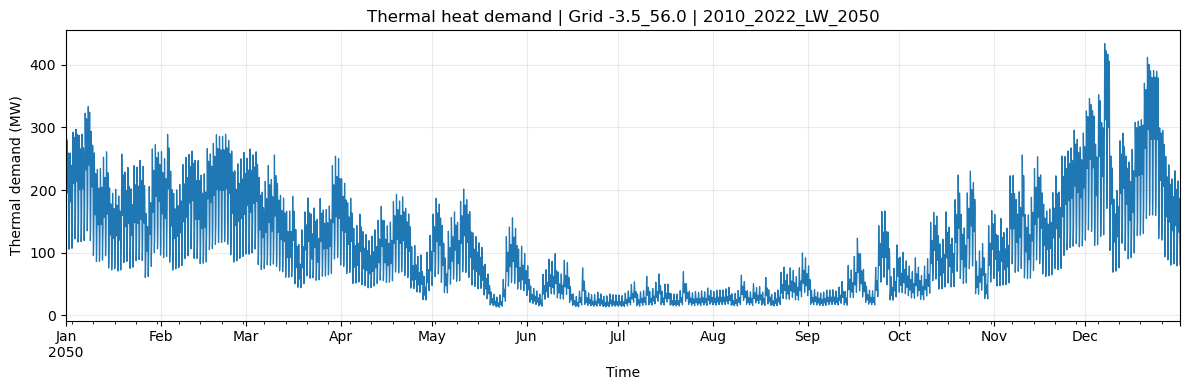

Total GB thermal heat demand: 222.766 TWh


In [4]:
heat_grid = HD_profiles[grid_id]
heat_grid_total_mw = heat_grid.sum(axis=1) * 2 / 1000

fig, ax = plt.subplots(figsize=(12, 4))
heat_grid_total_mw.plot(ax=ax, lw=0.9)
ax.set(title=f"Thermal heat demand | Grid {grid_id} | {run_id}",
       xlabel="Time", ylabel="Thermal demand (MW)")
ax.grid(alpha=0.25)
fig.tight_layout()
if save_notebook_figures:
    fig.savefig(figure_dir / "01_selected_grid_thermal_demand.png", dpi=200, bbox_inches="tight")
plt.show()

thermal_twh = sum(df.to_numpy(dtype=float).sum() for df in HD_profiles.values()) / 1e9
print(f"Total GB thermal heat demand: {thermal_twh:.3f} TWh")

## 5. Run the model COP calculation
The runner reads daily air temperature for the selected weather year and generates ASHP/GSHP COP profiles using the performance assumptions in `gbheatmodel.cop`.

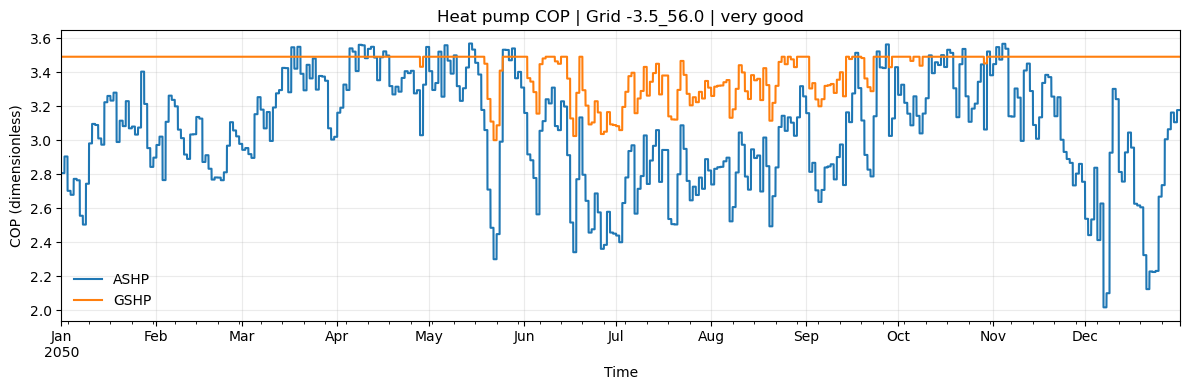

In [5]:
cop_profiles = run_cop_profiles(
    weather_year=weather_year,
    future_year=future_year,
    performance_level=performance_level,
    save=save_model_outputs,
)
df_cop_ASHP = cop_profiles["ASHP"]
df_cop_GSHP = cop_profiles["GSHP"]
for name, data in [("ASHP", df_cop_ASHP), ("GSHP", df_cop_GSHP)]:
    if grid_id not in data.columns:
        raise KeyError(f"Grid {grid_id} is missing from {name} COP profiles.")
    if not np.isfinite(data.to_numpy(dtype=float)).all() or (data.to_numpy(dtype=float) <= 0).any():
        raise ValueError(f"{name} COP contains invalid or non-positive values.")

fig, ax = plt.subplots(figsize=(12, 4))
for name, data in [("ASHP", df_cop_ASHP), ("GSHP", df_cop_GSHP)]:
    pd.Series(data[grid_id].to_numpy(), index=pd.to_datetime(data.index)).plot(ax=ax, label=name)
ax.set(title=f"Heat pump COP | Grid {grid_id} | {performance_level}",
       xlabel="Time", ylabel="COP (dimensionless)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
if save_notebook_figures:
    fig.savefig(figure_dir / "02_selected_grid_COP.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Calculate electricity demand through the existing runner
**Do not reimplement the electrical conversion in this notebook.** `run_electric_demand()` delegates to `gbheatmodel.electric_demand_for_heat`, including the existing hybrid technology assumptions. The final `weather_year` argument is mandatory.

In [6]:
ed_grid_sqs = run_electric_demand(
    HD_profiles=HD_profiles,
    df_cop_ASHP=df_cop_ASHP,
    df_cop_GSHP=df_cop_GSHP,
    FES_year=FES_year,
    scenario=FES_scenario,
    future_year=future_year,
    weather_year=weather_year,
    save=save_model_outputs,
)

if set(ed_grid_sqs) != set(HD_profiles):
    missing = sorted(set(HD_profiles) - set(ed_grid_sqs))
    unexpected = sorted(set(ed_grid_sqs) - set(HD_profiles))
    raise ValueError(f"Electricity demand grid mismatch. Missing={missing[:10]}, unexpected={unexpected[:10]}")

for grid, df in ed_grid_sqs.items():
    if not df.index.equals(HD_profiles[grid].index):
        raise ValueError(f"Heat/electric timestamps differ in grid {grid}.")
    if not np.isfinite(df.to_numpy(dtype=float)).all():
        raise ValueError(f"Missing or non-finite electricity demand in grid {grid}.")

print(f"Electricity demand created for {len(ed_grid_sqs)} grid squares.")
display(ed_grid_sqs[grid_id].head())

Electricity demand created for 738 grid squares.


,ASHP Elec,GSHP Elec,Hybrid (ASHP + BioLPG boiler) Elec,Hybrid (ASHP + Hydrogen boiler) Elec,Hybrid (ASHP + Electric resistive) Elec
2050-01-01 00:00:00,5194.176100,5757.931708,76.164995,29.645006,2648.523701
2050-01-01 00:30:00,5280.304642,5862.349595,77.032442,29.982635,2678.687875
2050-01-01 01:00:00,5431.665372,6024.279153,80.198690,31.215004,2788.789390
2050-01-01 01:30:00,5535.434694,6136.767717,81.848139,31.857004,2846.146507
2050-01-01 02:00:00,5722.803290,6314.695808,86.848665,33.803314,3020.032335


## 7. Consistency checks
Validate the direct ASHP/GSHP conversions independently. This check must match the existing runner results within floating-point tolerance; the hybrid technology conversions remain those implemented in `electric_demand.py`. The reported electrical total covers the technologies included by that function, **not every electrical heating technology in the full heating mix**.

In [7]:
electric_grid = ed_grid_sqs[grid_id]
ashp_cop = df_cop_ASHP[grid_id].copy()
gshp_cop = df_cop_GSHP[grid_id].copy()
ashp_cop.index = pd.to_datetime(ashp_cop.index)
gshp_cop.index = pd.to_datetime(gshp_cop.index)

expected_ashp = heat_grid["ASHP"] / ashp_cop.reindex(heat_grid.index)
expected_gshp = heat_grid["GSHP"] / gshp_cop.reindex(heat_grid.index)

np.testing.assert_allclose(
    electric_grid["ASHP Elec"].to_numpy(), expected_ashp.to_numpy(),
    rtol=1e-10, atol=1e-8,
)
np.testing.assert_allclose(
    electric_grid["GSHP Elec"].to_numpy(), expected_gshp.to_numpy(),
    rtol=1e-10, atol=1e-8,
)
print("PASS: ASHP and GSHP electric demand matches heat demand / COP at the selected grid.")

summary = pd.DataFrame({
    "Metric": ["Thermal heat demand (all grid/technology profiles)",
               "Electricity demand (technologies represented by electric_demand.py)",
               "Number of grid profiles", "Number of half-hourly intervals"],
    "Value": [thermal_twh,
              sum(df.to_numpy(dtype=float).sum() for df in ed_grid_sqs.values()) / 1e9,
              len(HD_profiles), len(heat_grid)],
    "Unit": ["TWh", "TWh", "grids", "intervals"],
})
display(summary)
if save_notebook_figures:
    summary.to_csv(figure_dir / "03_demand_summary.csv", index=False)

PASS: ASHP and GSHP electric demand matches heat demand / COP at the selected grid.


,Metric,Value,Unit
0,Thermal heat demand (all grid/technology profi...,222.766234,TWh
1,Electricity demand (technologies represented b...,47.329064,TWh
2,Number of grid profiles,738.000000,grids
3,Number of half-hourly intervals,17520.000000,intervals


## 8. Plot the modelled electrical demand
The electrical profiles reported here include the heat-pump and hybrid components currently returned by `electric_demand_for_heat`. They should not be described as total electricity demand of the GB power system.

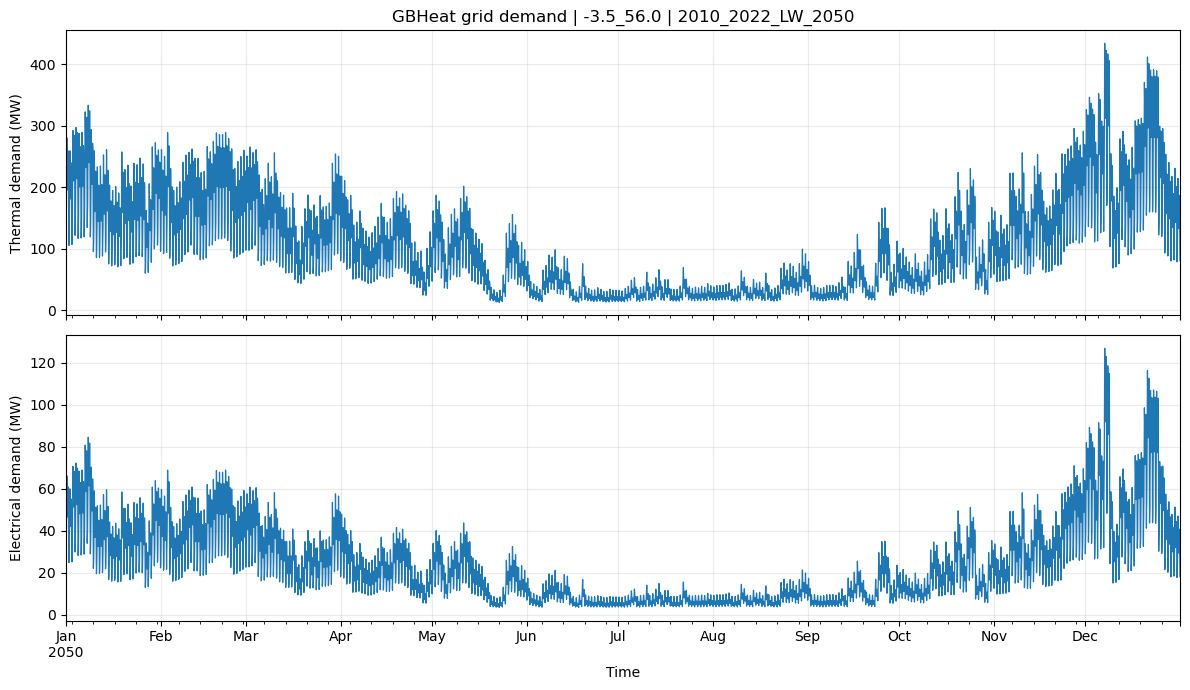

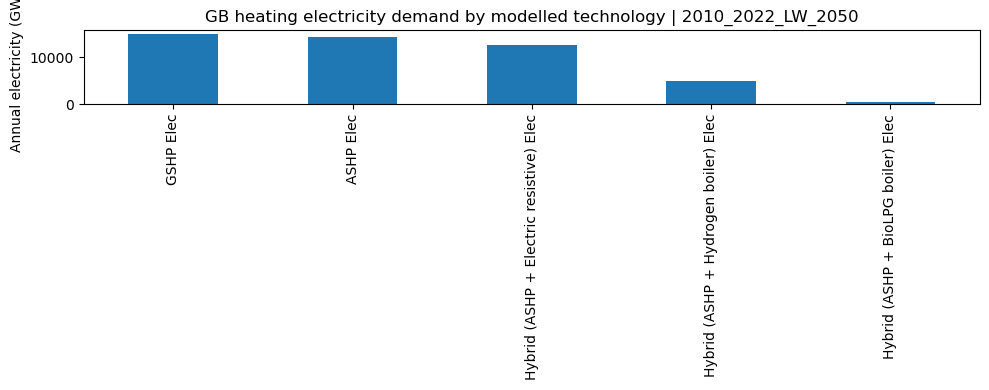

In [8]:
electric_grid_total_mw = electric_grid.sum(axis=1) * 2 / 1000
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
heat_grid_total_mw.plot(ax=axes[0], label="Thermal", lw=0.9)
electric_grid_total_mw.plot(ax=axes[1], label="Electrical", lw=0.9)
axes[0].set_ylabel("Thermal demand (MW)")
axes[1].set_ylabel("Electrical demand (MW)")
axes[1].set_xlabel("Time")
axes[0].set_title(f"GBHeat grid demand | {grid_id} | {run_id}")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
if save_notebook_figures:
    fig.savefig(figure_dir / "04_selected_grid_thermal_vs_electric.png", dpi=200, bbox_inches="tight")
plt.show()

technology_electric_gwh = pd.concat(ed_grid_sqs.values()).sum(axis=0) / 1e6
fig, ax = plt.subplots(figsize=(10, 4))
technology_electric_gwh.sort_values(ascending=False).plot.bar(ax=ax)
ax.set(title=f"GB heating electricity demand by modelled technology | {run_id}",
       ylabel="Annual electricity (GWh)", xlabel="")
fig.tight_layout()
if save_notebook_figures:
    fig.savefig(figure_dir / "05_electricity_by_technology.png", dpi=200, bbox_inches="tight")
    technology_electric_gwh.rename("Annual_Electricity_GWh").to_csv(
        figure_dir / "05_electricity_by_technology.csv"
    )
plt.show()

## Outputs and scientific notes

- **COP output:** `data/outputs/COP_Profiles/ASHP_<performance>_<weather_year>_<future_year>.csv` and equivalent GSHP file (when `save_model_outputs=True`).
- **Electricity output:** `data/outputs/electric_demand/<weather_year>_<FES_year>_<scenario>_<future_year>/` (when saving).
- **Notebook figures and tables:** `data/outputs/figures/<run_id>/02_COP_and_Electricity_Demand/`.
- **Units:** GBHeat heat/electric energy per step is assumed to be kWh per half-hour; GW/MW plots use the 30-minute conversion. COP is dimensionless.
- **Scope:** The electrical conversion represents the ASHP, GSHP and hybrid heating columns handled by the uploaded `electric_demand.py`. Direct electric resistance/storage heating outside that function is not included in its reported total. All methodological changes should be made and tested in the source model, not separately inside a notebook.

**Validation limitation:** Source-level checks have been added, but executing this notebook end-to-end requires your GBHeat dataset and full package. Compare outputs with a known reference run before public release.